# Examen Parcial - Informe 03 - Redes Neuronales Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo**
**Riveros Ruiz, Jason Wilmer**
**Torres Vela, Juan Carlos (Representante)**
**Zavala Suyo, Rafael**

---
**Prof. Dr.    Aldo Camargo**

---
# 02 · Entrenamiento y evaluación del detector YOLO (modelo base)

**Objetivo:** entrenar un detector de especies con YOLOv8 (o YOLOv9) y evaluarlo **dentro de las mismas cámaras (`cis_val`)** y en **cámaras nunca vistas (`trans_val`)**.

**Cómo se aborda el desbalance de clases** (enunciado):
1. **Vacías limitadas en train** (15 % en vez de ~70 %) y usadas como *imágenes de fondo* (etiqueta vacía → el modelo aprende a no disparar).
2. **Repeat Factor Sampling (RFS):** las imágenes con especies raras se repiten más veces por época: `r_c = max(1, sqrt(t / f_c))`.
3. **Métricas por clase** (no solo mAP global) y métricas a nivel de imagen *hay fauna / vacía*.

**Requisito:** GPU T4. Haber ejecutado el notebook 01.

In [ ]:
!pip -q install -U ultralytics
import os, sys, json, math, shutil, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
warnings.filterwarnings('ignore')

# 1) Montar Drive PRIMERO (antes de buscar cct_utils.py)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

# 2) Localizar la carpeta del proyecto: la que contiene cct_utils.py
#    (el notebook 01 la crea en MyDrive/cct_yolo; se prueban también otros nombres comunes)
CANDIDATES = [os.environ.get('CCT_DRIVE_DIR'),
              '/content/drive/MyDrive/cct_yolo',
              '/content/drive/MyDrive/Dfoto',
              '/content/drive/MyDrive/Dfoto/cct_yolo']
DRIVE_DIR = next((Path(p) for p in CANDIDATES if p and (Path(p) / 'cct_utils.py').exists()), None)
if DRIVE_DIR is None:  # búsqueda de respaldo en todo MyDrive
    hits = sorted(Path('/content/drive/MyDrive').glob('**/cct_utils.py'))
    DRIVE_DIR = hits[0].parent if hits else None
if DRIVE_DIR is None:
    raise FileNotFoundError(
        'No se encontró cct_utils.py en tu Drive. Ejecuta primero el notebook 01 '
        '(celda 2 crea cct_utils.py) o sube el archivo a MyDrive/cct_yolo.')
os.environ['CCT_DRIVE_DIR'] = str(DRIVE_DIR)
print('Carpeta del proyecto:', DRIVE_DIR)

sys.path.insert(0, str(DRIVE_DIR))
import importlib
import cct_utils as U
importlib.reload(U)   # por si Colab ya tenía una versión en memoria
U.init()
U.ensure_dataset()
U.load_classes()
meta = U.load_meta()
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO HAY GPU (Entorno de ejecución > Cambiar tipo > T4)')
print(meta.groupby('split').size().to_dict())


Mounted at /content/drive
Carpeta del proyecto: /content/drive/MyDrive/Dfoto
Restaurando dataset desde Drive (puede tardar unos minutos)...
Dataset restaurado en /content/cct
GPU: Tesla T4
{'cis_val': 3875, 'train': 14065, 'trans_val': 9895}


## 1. Configuración del experimento

In [ ]:
RUN = 'baseline'
MODEL = 'yolov8s.pt'      # alternativas: 'yolov9c.pt' (más pesado, batch 16), 'yolov8m.pt', 'yolo11s.pt'
EPOCHS = 30
BATCH = 32
PATIENCE = 8
USE_RFS = True
REPEAT_T = 0.05           # umbral t de RFS: clases con f_c < t se sobremuestrean
REPEAT_MAX = 6            # tope de repeticiones por imagen
BASE_AUG = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, degrees=0.0, translate=0.1, scale=0.5,
                fliplr=0.5, mosaic=1.0, mixup=0.1)
CONF_FOR_IMAGE_LEVEL = 0.25   # se recalcula más abajo con cis_val
CONFIG = dict(run=RUN, model=MODEL, epochs=EPOCHS, batch=BATCH, patience=PATIENCE,
              use_rfs=USE_RFS, repeat_t=REPEAT_T, repeat_max=REPEAT_MAX, aug=BASE_AUG,
              imgsz=U.IMGSZ, seed=U.SEED)

## 2. Desbalance en la partición de entrenamiento

In [ ]:
mt = meta[meta.split == 'train']
n_img = Counter(c for s in mt.species for c in set(s.split('|')) if c)
inst_train = U.count_instances('train')
tab = pd.DataFrame({'imagenes_train': pd.Series(n_img), 'instancias_train': pd.Series(inst_train)}).fillna(0).astype(int)
tab = tab.reindex(U.CLASSES).fillna(0).astype(int).sort_values('imagenes_train', ascending=False)
print(f"Imágenes de train: {len(mt):,} | vacías (fondo): {(mt.n_boxes == 0).mean():.1%}")
print(tab.to_string())
nz = tab[tab.imagenes_train > 0]
print(f"\nRazón de desbalance (imágenes) máx/mín = {nz.imagenes_train.max() / nz.imagenes_train.min():.0f}x")
if (tab.imagenes_train == 0).any():
    print('ATENCIÓN: clases sin ejemplos en train (no se podrán aprender):', tab[tab.imagenes_train == 0].index.tolist())

Imágenes de train: 14,065 | vacías (fondo): 10.2%
               imagenes_train  instancias_train
opossum                  2398              2404
rabbit                   2190              2257
coyote                   1535              1631
raccoon                  1091              1172
bobcat                    893               904
cat                       848               855
squirrel                  833               845
car                       752               752
dog                       734               817
bird                      707              1058
rodent                    260               264
skunk                     259               259
deer                      124               128
badger                      5                 5
fox                         3                 3
bat                         0                 0
insect                      0                 0
lizard                      0                 0
mountain_lion               0         

## 3. Repeat Factor Sampling
Se materializa como una carpeta `images/train_rfs` con enlaces simbólicos (las imágenes raras aparecen varias veces con otro nombre).

In [ ]:
if USE_RFS:
    r_c, n_extra = U.build_rfs_dir(mt, t=REPEAT_T, rmax=REPEAT_MAX)
    print(f'Copias extra añadidas: {n_extra:,} (train pasa de {len(mt):,} a {len(mt) + n_extra:,} imágenes por época)')
    print(pd.Series(r_c).sort_values(ascending=False).round(2).to_string())
TRAIN_DIR = 'images/train_rfs' if USE_RFS else 'images/train'

Copias extra añadidas: 555 (train pasa de 14,065 a 14,620 imágenes por época)
fox         15.31
badger      11.86
deer         2.38
skunk        1.65
rodent       1.64
opossum      1.00
squirrel     1.00
dog          1.00
cat          1.00
bird         1.00
raccoon      1.00
coyote       1.00
rabbit       1.00
bobcat       1.00
car          1.00


## 4. Entrenamiento
- `val` durante el entrenamiento usa **`cis_val`** (selección de *epoch*). `trans_val` no se toca para no sesgar la medición de generalización.
- Los pesos y curvas se guardan en Drive (`cct_yolo/runs/<RUN>`). Si Colab se desconecta, usa la celda de reanudación.

In [ ]:
from ultralytics import YOLO
train_yaml = U.make_yaml(f'train_{RUN}', train=TRAIN_DIR, val='images/cis_val')
model = YOLO(MODEL)
results = model.train(
    data=str(train_yaml), epochs=EPOCHS, imgsz=U.IMGSZ, batch=BATCH, patience=PATIENCE,
    project=str(U.DRIVE_DIR / 'runs'), name=RUN, exist_ok=True, seed=U.SEED,
    cos_lr=True, close_mosaic=5, workers=4, amp=True, plots=True,
    **BASE_AUG)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/cct/train_baseline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

In [ ]:
# (Opcional) reanudar tras una desconexión:
YOLO(str(U.DRIVE_DIR / 'runs' / RUN / 'weights' / 'last.pt')).train(resume=True)

WARNING ⚠️ model '/content/drive/MyDrive/Dfoto/runs/baseline/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, l

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0, 16, 17, 20, 25, 58])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c5ece096270>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

### Curvas de entrenamiento

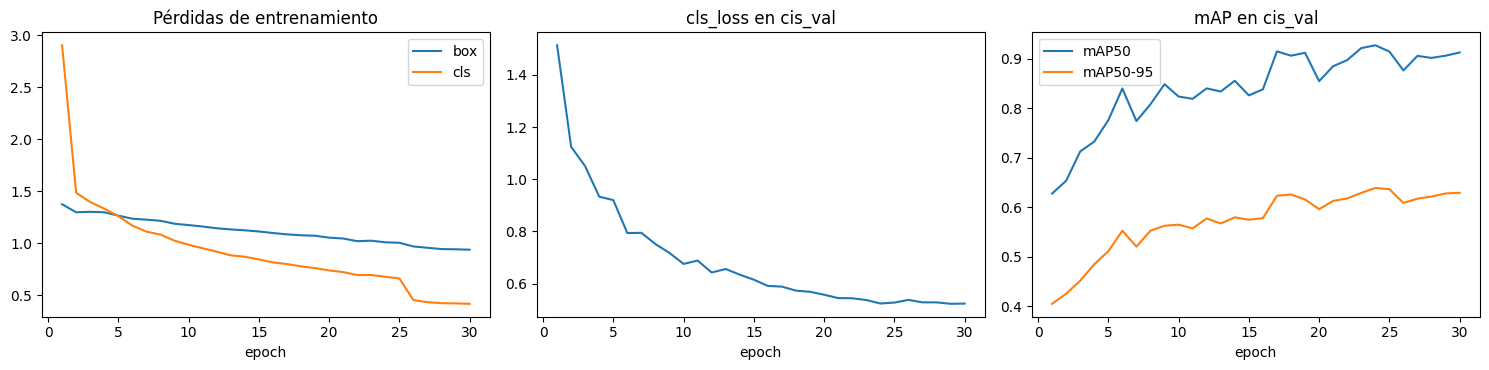

In [ ]:
BEST = U.DRIVE_DIR / 'runs' / RUN / 'weights' / 'best.pt'
res_csv = pd.read_csv(U.DRIVE_DIR / 'runs' / RUN / 'results.csv')
res_csv.columns = [c.strip() for c in res_csv.columns]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(res_csv['epoch'], res_csv['train/box_loss'], label='box'); ax[0].plot(res_csv['epoch'], res_csv['train/cls_loss'], label='cls')
ax[0].set_title('Pérdidas de entrenamiento'); ax[0].legend()
ax[1].plot(res_csv['epoch'], res_csv['val/cls_loss']); ax[1].set_title('cls_loss en cis_val')
ax[2].plot(res_csv['epoch'], res_csv['metrics/mAP50(B)'], label='mAP50'); ax[2].plot(res_csv['epoch'], res_csv['metrics/mAP50-95(B)'], label='mAP50-95')
ax[2].set_title('mAP en cis_val'); ax[2].legend()
for a in ax: a.set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 5. Evaluación: misma cámara (`cis_val`) vs. cámara nueva (`trans_val`)

In [ ]:
res = {s: U.eval_detector(BEST, s, RUN) for s in ['cis_val', 'trans_val']}
glob = pd.DataFrame({s: {k: v for k, v in r.items() if k not in ('per_class', 'split')} for s, r in res.items()}).T
glob['gap_mAP50(cis-trans)'] = [np.nan, np.nan]
glob.loc['trans_val', 'gap_mAP50(cis-trans)'] = res['cis_val']['map50'] - res['trans_val']['map50']
print(glob.round(3).to_string())

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1835.7±637.3 MB/s, size: 88.3 KB)
val: Scanning /content/cct/labels/cis_val.cache... 3875 images, 309 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3875/3875 1.4Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 122/122 2.7it/s 44.7s
                   all       3875       3747      0.919      0.806      0.927      0.638
Speed: 0.9ms preprocess, 7.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/Dfoto/eval/baseline_cis_val
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,132,937 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 14.3±7.8 MB/s

               inst_train  inst_cis_val  AP50_cis_val  R_cis_val  inst_trans_val  AP50_trans_val  R_trans_val  gap_AP50
opossum            2404.0         893.0         0.974      0.935          2415.0           0.896        0.793     0.078
rabbit             2257.0         592.0         0.972      0.955           185.0           0.593        0.638     0.378
coyote             1631.0         409.0         0.973      0.946           932.0           0.572        0.745     0.401
raccoon            1172.0         309.0         0.982      0.958          1881.0           0.749        0.646     0.233
bird               1058.0         190.0         0.761      0.716            70.0           0.060        0.143     0.701
bobcat              904.0         236.0         0.945      0.901          1473.0           0.757        0.525     0.188
cat                 855.0         326.0         0.959      0.920           728.0           0.301        0.400     0.658
squirrel            845.0         214.0 

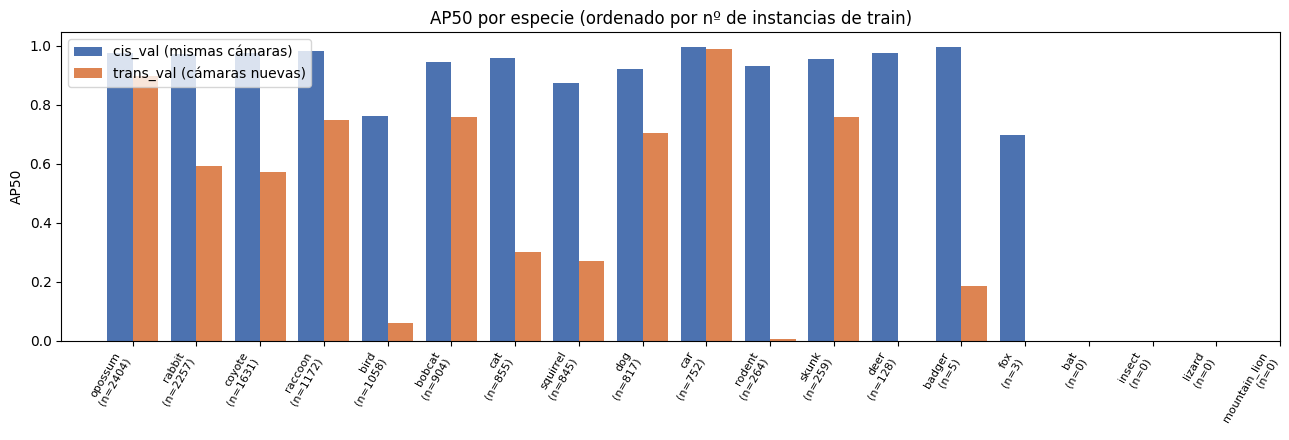

In [ ]:
# Detalle por clase
inst = {s: U.count_instances(s) for s in ['cis_val', 'trans_val']}
pc = pd.DataFrame(index=U.CLASSES)
pc['inst_train'] = pd.Series(inst_train)
for s in ['cis_val', 'trans_val']:
    pc[f'inst_{s}'] = pd.Series(inst[s])
    pc[f'AP50_{s}'] = pd.Series({c: v['ap50'] for c, v in res[s]['per_class'].items()})
    pc[f'R_{s}'] = pd.Series({c: v['r'] for c, v in res[s]['per_class'].items()})
pc = pc.fillna({'inst_train': 0, 'inst_cis_val': 0, 'inst_trans_val': 0}).sort_values('inst_train', ascending=False)
pc['gap_AP50'] = pc['AP50_cis_val'] - pc['AP50_trans_val']
print(pc.round(3).to_string())
(U.DRIVE_DIR / 'summaries').mkdir(exist_ok=True)
pc.to_csv(U.DRIVE_DIR / 'summaries' / f'{RUN}_por_clase.csv')

fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(pc)); w = 0.4
ax.bar(x - w/2, pc['AP50_cis_val'], w, label='cis_val (mismas cámaras)', color='#4C72B0')
ax.bar(x + w/2, pc['AP50_trans_val'], w, label='trans_val (cámaras nuevas)', color='#DD8452')
ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={int(n)})" for c, n in zip(pc.index, pc['inst_train'])], rotation=60, ha='right', fontsize=8)
ax.set_ylabel('AP50'); ax.set_title('AP50 por especie (ordenado por nº de instancias de train)'); ax.legend()
plt.tight_layout(); plt.show()

**Matriz de confusión** (generada por Ultralytics al evaluar; la fila/columna *background* muestra falsos positivos y falsos negativos).

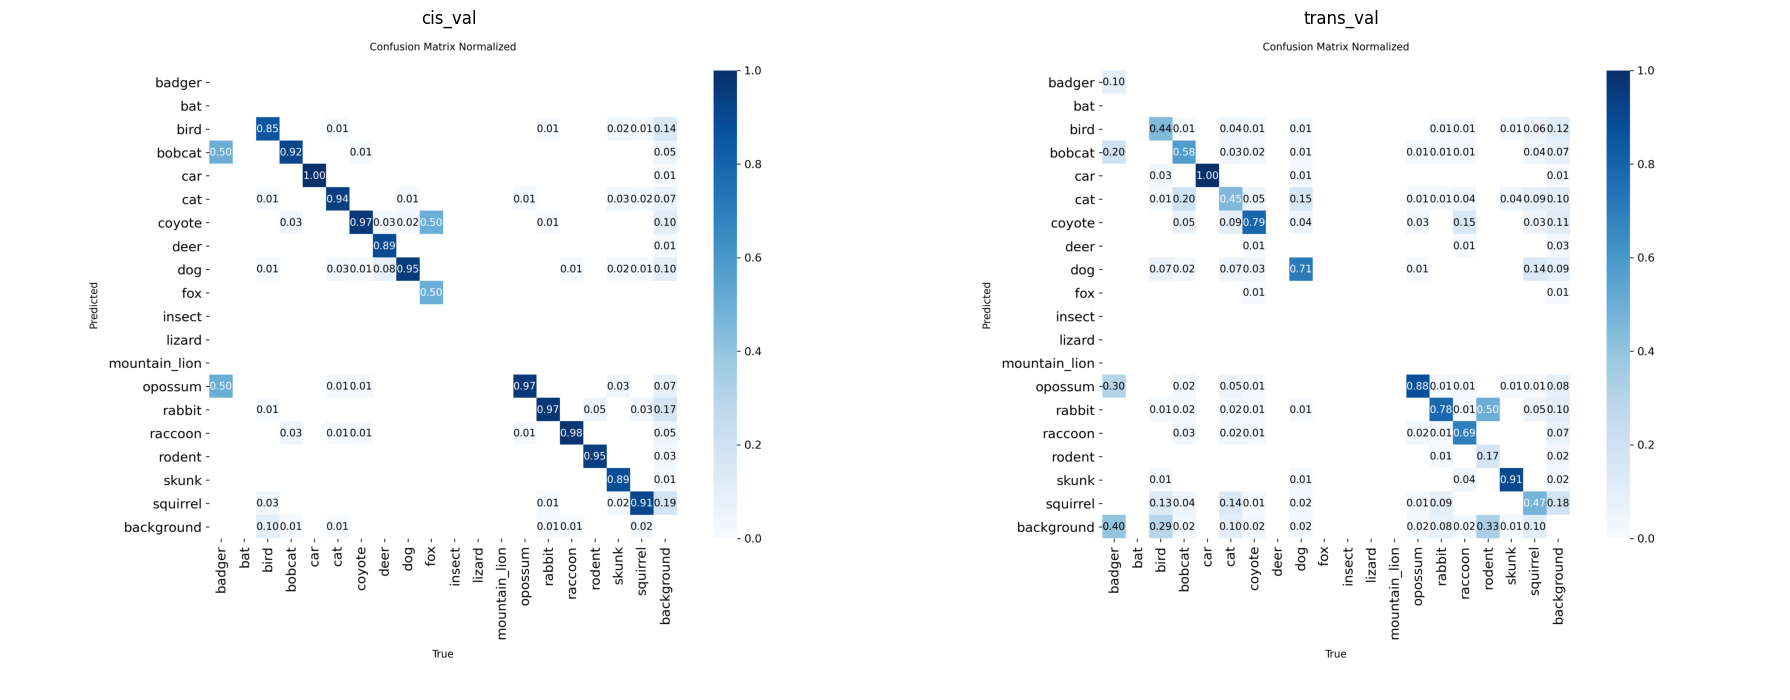

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a, s in zip(ax, ['cis_val', 'trans_val']):
    p = U.DRIVE_DIR / 'eval' / f'{RUN}_{s}' / 'confusion_matrix_normalized.png'
    if p.exists():
        a.imshow(plt.imread(p)); a.set_title(s)
    a.axis('off')
plt.tight_layout(); plt.show()

## 5.1 Entregable 2 · Evaluación cuantitativa en el conjunto de prueba, por especie y efecto del desbalance

**Definición de los conjuntos (para que el informe sea inequívoco)**

| Conjunto | Partición | Cámaras | Uso |
|---|---|---|---|
| **Prueba (test)** | `trans_val` (`eccv_val`) | **nunca vistas** | solo reporte: no se usa para elegir epoch, umbrales ni hiperparámetros |
| Validación | `cis_val` | las mismas de entrenamiento (otras secuencias) | selección de `best.pt` (early stopping). Sus métricas son algo **optimistas** |

Métricas: **mAP@0.5** y **mAP@0.5:0.95** (COCO, `conf=0.001`, `iou=0.6`). El promedio *macro* da el mismo peso a cada especie; el promedio *ponderado por instancias* se parece a lo que vería un usuario que cuenta animales y está dominado por las especies comunes. **La diferencia entre ambos es la primera medida del efecto del desbalance.**

In [ ]:
# ---------- 5.1.a  Métricas globales: mAP@0.5 y mAP@0.5:0.95 ----------
from scipy.stats import spearmanr

TEST_SPLIT, VAL_SPLIT = 'trans_val', 'cis_val'
NAMES = {TEST_SPLIT: 'PRUEBA  · trans_val (cámaras nuevas)', VAL_SPLIT: 'VALIDACIÓN · cis_val (mismas cámaras)'}

glob2 = pd.DataFrame({
    NAMES[s]: {'mAP@0.5': res[s]['map50'], 'mAP@0.5:0.95': res[s]['map50_95'],
               'Precisión': res[s]['precision'], 'Recall': res[s]['recall'],
               'especies con GT': int(len(res[s]['per_class']))}
    for s in [TEST_SPLIT, VAL_SPLIT]}).T
print('MÉTRICAS GLOBALES (promedio macro sobre las especies presentes en cada conjunto)')
print(glob2.round(3).to_string())
(U.DRIVE_DIR / 'summaries').mkdir(exist_ok=True)
glob2.to_csv(U.DRIVE_DIR / 'summaries' / f'{RUN}_entregable2_global.csv')

MÉTRICAS GLOBALES (promedio macro sobre las especies presentes en cada conjunto)
                                       mAP@0.5  mAP@0.5:0.95  Precisión  Recall  especies con GT
PRUEBA  · trans_val (cámaras nuevas)     0.526         0.362      0.597   0.519             13.0
VALIDACIÓN · cis_val (mismas cámaras)    0.927         0.638      0.919   0.806             15.0


In [ ]:
# ---------- 5.1.b  Tabla por especie (prueba y validación) + nivel de desbalance ----------
COMMON_MIN = 1000      # instancias de train a partir de las cuales una especie es "común"
RARE_MAX = 100         # por debajo de este número de instancias de train es "rara"
MIN_TEST_INST = 20     # por debajo de esto el AP en prueba es poco fiable (se marca con *)

inst_all = {s: U.count_instances(s) for s in ['train', 'cis_val', 'trans_val']}
img_train = Counter(c for s_ in meta[meta.split == 'train'].species for c in set(s_.split('|')) if c)

def tier_of(n):
    if n == 0:
        return '0 · sin ejemplos'
    return '1 · común' if n >= COMMON_MIN else ('3 · rara' if n < RARE_MAX else '2 · intermedia')

rows = []
for c in U.CLASSES:
    d = dict(especie=c, inst_train=inst_all['train'].get(c, 0), img_train=img_train.get(c, 0))
    d['grupo'] = tier_of(d['inst_train'])
    for s, tag in [(TEST_SPLIT, 'test'), (VAL_SPLIT, 'val')]:
        pcr = res[s]['per_class'].get(c)
        d[f'inst_{tag}'] = inst_all[s].get(c, 0)
        d[f'AP50_{tag}'] = pcr['ap50'] if pcr else np.nan
        d[f'AP50_95_{tag}'] = pcr['ap'] if pcr else np.nan
        d[f'P_{tag}'] = pcr['p'] if pcr else np.nan
        d[f'R_{tag}'] = pcr['r'] if pcr else np.nan
    rows.append(d)
E2 = pd.DataFrame(rows).sort_values('inst_train', ascending=False).reset_index(drop=True)
E2['test_fiable'] = E2['inst_test'] >= MIN_TEST_INST
E2['inst_train/total'] = E2['inst_train'] / E2['inst_train'].sum()

show_cols = ['especie', 'grupo', 'inst_train', 'inst_test', 'AP50_test', 'AP50_95_test', 'P_test', 'R_test',
             'AP50_val', 'AP50_95_val']
tbl = E2[show_cols].copy()
tbl['especie'] = [f'{e}{"" if f else " *"}' for e, f in zip(E2['especie'], E2['test_fiable'])]
print('RESULTADOS POR ESPECIE (ordenados por nº de instancias de entrenamiento)')
print(tbl.round(3).to_string(index=False))
print(f'\n* = menos de {MIN_TEST_INST} instancias en el conjunto de prueba: el AP de esa especie es muy ruidoso.')
print('NaN = la especie no tiene ninguna instancia en ese conjunto (no se puede calcular AP).')
print('Grupos:', E2.groupby('grupo').especie.apply(lambda s: ', '.join(s)).to_dict())
E2.to_csv(U.DRIVE_DIR / 'summaries' / f'{RUN}_entregable2_por_especie.csv', index=False)

RESULTADOS POR ESPECIE (ordenados por nº de instancias de entrenamiento)
        especie            grupo  inst_train  inst_test  AP50_test  AP50_95_test  P_test  R_test  AP50_val  AP50_95_val
        opossum        1 · común        2404       2415      0.896         0.459   0.956   0.793     0.974        0.553
         rabbit        1 · común        2257        185      0.593         0.339   0.623   0.638     0.972        0.641
         coyote        1 · común        1631        932      0.572         0.411   0.585   0.745     0.973        0.738
        raccoon        1 · común        1172       1881      0.749         0.499   0.935   0.646     0.982        0.706
           bird        1 · común        1058         70      0.060         0.035   0.138   0.143     0.761        0.420
         bobcat   2 · intermedia         904       1473      0.757         0.516   0.903   0.525     0.945        0.690
            cat   2 · intermedia         855        728      0.301         0.197   0.38

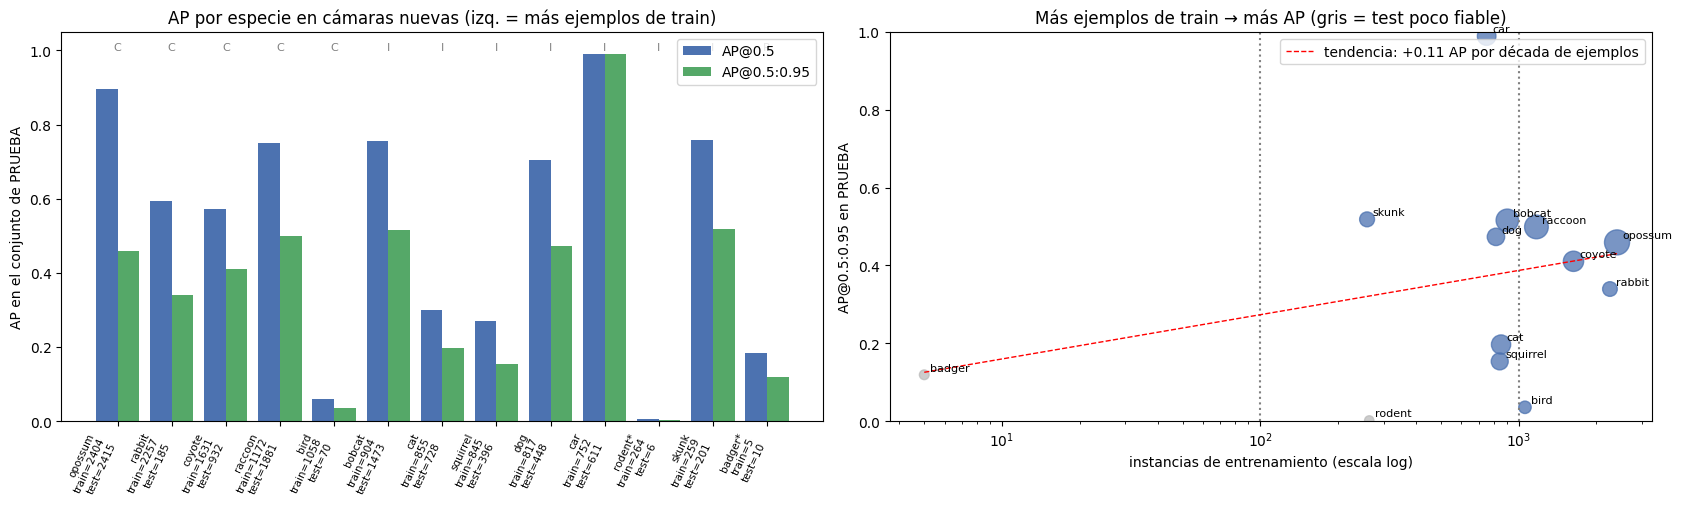

In [ ]:
# ---------- 5.1.c  Gráficos: AP por especie y relación AP vs. nº de ejemplos de train ----------
(U.DRIVE_DIR / 'figs').mkdir(exist_ok=True)
T = E2[E2.inst_test > 0].copy()
fig, ax = plt.subplots(1, 2, figsize=(17, 5.2))

x = np.arange(len(T)); w = 0.4
ax[0].bar(x - w/2, T['AP50_test'], w, label='AP@0.5', color='#4C72B0')
ax[0].bar(x + w/2, T['AP50_95_test'], w, label='AP@0.5:0.95', color='#55A868')
ax[0].set_xticks(x)
ax[0].set_xticklabels([f"{e}{'' if f else '*'}\ntrain={n}\ntest={m}" for e, f, n, m in
                       zip(T.especie, T.test_fiable, T.inst_train, T.inst_test)], rotation=65, ha='right', fontsize=7.5)
ax[0].set_ylim(0, 1.05); ax[0].set_ylabel('AP en el conjunto de PRUEBA'); ax[0].legend()
ax[0].set_title('AP por especie en cámaras nuevas (izq. = más ejemplos de train)')
for xi, g in zip(x, T['grupo']):
    ax[0].text(xi, 1.0, {'1': 'C', '2': 'I', '3': 'R', '0': '0'}[g[0]], ha='center', fontsize=8, color='gray')

Tp = T[T.inst_train > 0]
ax[1].scatter(Tp['inst_train'], Tp['AP50_95_test'], s=30 + 6 * np.sqrt(Tp['inst_test']), alpha=.75,
              c=['#4C72B0' if f else '#BBBBBB' for f in Tp['test_fiable']])
for r in Tp.itertuples():
    ax[1].annotate(r.especie, (r.inst_train, r.AP50_95_test), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax[1].set_xscale('log'); ax[1].set_xlabel('instancias de entrenamiento (escala log)')
ax[1].set_ylabel('AP@0.5:0.95 en PRUEBA'); ax[1].set_ylim(0, 1.0)
ax[1].axvline(RARE_MAX, ls=':', c='gray'); ax[1].axvline(COMMON_MIN, ls=':', c='gray')
if len(Tp) >= 4:
    k, b = np.polyfit(np.log10(Tp['inst_train']), Tp['AP50_95_test'], 1)
    xs = np.logspace(np.log10(Tp.inst_train.min()), np.log10(Tp.inst_train.max()), 50)
    ax[1].plot(xs, k * np.log10(xs) + b, 'r--', lw=1, label=f'tendencia: {k:+.2f} AP por década de ejemplos')
    ax[1].legend()
ax[1].set_title('Más ejemplos de train → más AP (gris = test poco fiable)')
plt.tight_layout(); plt.savefig(U.DRIVE_DIR / 'figs' / f'{RUN}_entregable2_ap_vs_desbalance.png', dpi=150); plt.show()

In [ ]:
# ---------- 5.1.d  Cuantificación explícita del efecto del desbalance ----------
rng_b = np.random.default_rng(0)
def boot_ci(vals, n=5000):
    vals = np.asarray(vals, float); vals = vals[~np.isnan(vals)]
    if len(vals) < 2:
        return (np.nan, np.nan)
    m = [rng_b.choice(vals, len(vals)).mean() for _ in range(n)]
    return tuple(np.percentile(m, [2.5, 97.5]))

T = E2[E2.inst_test > 0].copy()
print('1) MACRO vs. PONDERADO POR INSTANCIAS (prueba)')
rows = []
for met in ['AP50_test', 'AP50_95_test']:
    macro = T[met].mean()
    wavg = np.average(T[met].fillna(0), weights=T['inst_test'])
    rows.append(dict(metrica=met.replace('_test', ''), macro=macro, ponderado_por_instancias=wavg,
                     diferencia=wavg - macro))
print(pd.DataFrame(rows).round(3).to_string(index=False))
print('   Si "ponderado" >> "macro", el rendimiento global lo sostienen las especies comunes y el mAP macro (el oficial) es el que castiga a las raras.\n')

print('2) POR GRUPO DE FRECUENCIA EN ENTRENAMIENTO (prueba)')
g = (T.groupby('grupo').agg(especies=('especie', 'size'), inst_train_media=('inst_train', 'mean'), inst_test=('inst_test', 'sum'),
                            AP50=('AP50_test', 'mean'), AP50_95=('AP50_95_test', 'mean'),
                            recall=('R_test', 'mean'), precision=('P_test', 'mean')))
print(g.round(3).to_string())
for grp in g.index:
    lo, hi = boot_ci(T[T.grupo == grp]['AP50_95_test'])
    print(f'   {grp}: AP50-95 medio IC95% bootstrap sobre especies = [{lo:.3f}, {hi:.3f}] (n={int((T.grupo == grp).sum())})')
comm, rare = T[T.grupo.str.startswith('1')], T[T.grupo.str.startswith('3')]
if len(comm) and len(rare):
    print(f'   → Brecha comunes − raras: ΔAP50 = {comm.AP50_test.mean() - rare.AP50_test.mean():+.3f} | '
          f'ΔAP50-95 = {comm.AP50_95_test.mean() - rare.AP50_95_test.mean():+.3f} | '
          f'Δrecall = {comm.R_test.mean() - rare.R_test.mean():+.3f}')
else:
    print('   (Algún grupo está vacío: ajusta COMMON_MIN / RARE_MAX en la celda 5.1.b.)')

print('\n3) CORRELACIÓN AP vs. log10(instancias de train)')
Tp = T[T.inst_train > 0]
for met in ['AP50_test', 'AP50_95_test']:
    rho, pv = spearmanr(np.log10(Tp['inst_train']), Tp[met])
    print(f'   Spearman ρ({met}, log n_train) = {rho:+.2f}  (p={pv:.3f}, n={len(Tp)} especies)')
Tf = Tp[Tp.test_fiable]
if len(Tf) >= 4:
    rho, pv = spearmanr(np.log10(Tf['inst_train']), Tf['AP50_95_test'])
    print(f'   Solo especies con ≥{MIN_TEST_INST} instancias en prueba: ρ(AP50-95) = {rho:+.2f} (p={pv:.3f}, n={len(Tf)})')

# 4) ¿A dónde van las instancias de las especies raras? (matriz de confusión a conf=0.25; filas = predicción, columnas = verdad)
try:
    yml_t = U.make_yaml('eval_confusion_test', 'images/train', f'images/{TEST_SPLIT}')
    rr = YOLO(str(BEST)).val(data=str(yml_t), imgsz=U.IMGSZ, batch=BATCH, conf=0.25, iou=0.6, plots=False, verbose=False,
                             project=str(U.LOCAL / 'tmp_eval'), name='cm_test', exist_ok=True)
    cm = np.array(rr.confusion_matrix.matrix, dtype=float); nc = len(U.CLASSES)
    assert cm.shape == (nc + 1, nc + 1), cm.shape
    conf_rows = []
    for i, c in enumerate(U.CLASSES):
        tot = cm[:, i].sum()
        if tot == 0:
            continue
        others = cm[:nc, i].copy(); others[i] = 0
        j = int(others.argmax())
        conf_rows.append(dict(especie=c, inst_test_cm=int(tot), acierta=cm[i, i] / tot, perdida_como_fondo=cm[nc, i] / tot,
                              confundida_con_otra_especie=others.sum() / tot,
                              confundida_sobre_todo_con=U.CLASSES[j] if others[j] > 0 else '-'))
    CF = pd.DataFrame(conf_rows).merge(E2[['especie', 'inst_train', 'grupo']], on='especie').sort_values('inst_train', ascending=False)
    print('\n4) DESTINO DE LAS INSTANCIAS DE PRUEBA POR ESPECIE (conf = 0.25)')
    print(CF.round(3).to_string(index=False))
    print('   Diagnóstico: "perdida_como_fondo" alta = el detector ni siquiera la propone; '
          '"confundida_con_otra_especie" alta = la ve pero la asigna a una especie más frecuente.')
    CF.to_csv(U.DRIVE_DIR / 'summaries' / f'{RUN}_entregable2_destino_instancias.csv', index=False)
except Exception as e:
    print('\n4) No se pudo calcular el destino de las instancias (versión de Ultralytics distinta):', repr(e))

1) MACRO vs. PONDERADO POR INSTANCIAS (prueba)
metrica  macro  ponderado_por_instancias  diferencia
   AP50  0.526                     0.720       0.194
AP50_95  0.362                     0.468       0.106
   Si "ponderado" >> "macro", el rendimiento global lo sostienen las especies comunes y el mAP macro (el oficial) es el que castiga a las raras.

2) POR GRUPO DE FRECUENCIA EN ENTRENAMIENTO (prueba)
                especies  inst_train_media  inst_test   AP50  AP50_95  recall  precision
grupo                                                                                   
1 · común              5          1704.400       5483  0.574    0.349   0.593      0.648
2 · intermedia         7           670.857       3863  0.540    0.407   0.526      0.564
3 · rara               1             5.000         10  0.185    0.119   0.100      0.577
   1 · común: AP50-95 medio IC95% bootstrap sobre especies = [0.181, 0.465] (n=5)
   2 · intermedia: AP50-95 medio IC95% bootstrap sobre especies = [0

In [ ]:
# ---------- 5.1.e  Texto automático para el informe (revisar y completar) ----------
T = E2[E2.inst_test > 0]
Tn = T[T.test_fiable]
best3 = Tn.sort_values('AP50_95_test', ascending=False).head(3)
worst3 = Tn.sort_values('AP50_95_test').head(3)
print(f"En el conjunto de PRUEBA (cámaras nunca vistas) el modelo '{RUN}' obtiene mAP@0.5 = {res[TEST_SPLIT]['map50']:.3f} y "
      f"mAP@0.5:0.95 = {res[TEST_SPLIT]['map50_95']:.3f} (validación en las mismas cámaras: {res[VAL_SPLIT]['map50']:.3f} / "
      f"{res[VAL_SPLIT]['map50_95']:.3f}).")
print('Mejores especies (≥%d inst. en prueba): ' % MIN_TEST_INST + '; '.join(
    f'{r.especie} (AP50={r.AP50_test:.2f}, n_train={r.inst_train})' for r in best3.itertuples()))
print('Peores especies  (≥%d inst. en prueba): ' % MIN_TEST_INST + '; '.join(
    f'{r.especie} (AP50={r.AP50_test:.2f}, n_train={r.inst_train})' for r in worst3.itertuples()))
print(f"Razón de desbalance en train (máx/mín instancias): "
      f"{E2[E2.inst_train > 0].inst_train.max() / E2[E2.inst_train > 0].inst_train.min():.0f}x. "
      f"Se mitigó con vacías limitadas al {(mt.n_boxes == 0).mean():.0%} y RFS (t={REPEAT_T}, máx {REPEAT_MAX} copias); "
      f"el efecto residual es el medido arriba.")
print('Cuidado al interpretar: con pocas instancias de prueba el AP de una especie puede oscilar mucho; '
      'comparar grupos y tendencias, no especies individuales con *.')

En el conjunto de PRUEBA (cámaras nunca vistas) el modelo 'baseline' obtiene mAP@0.5 = 0.526 y mAP@0.5:0.95 = 0.362 (validación en las mismas cámaras: 0.927 / 0.638).
Mejores especies (≥20 inst. en prueba): car (AP50=0.99, n_train=752); skunk (AP50=0.76, n_train=259); bobcat (AP50=0.76, n_train=904)
Peores especies  (≥20 inst. en prueba): bird (AP50=0.06, n_train=1058); squirrel (AP50=0.27, n_train=845); cat (AP50=0.30, n_train=855)
Razón de desbalance en train (máx/mín instancias): 801x. Se mitigó con vacías limitadas al 10% y RFS (t=0.05, máx 6 copias); el efecto residual es el medido arriba.
Cuidado al interpretar: con pocas instancias de prueba el AP de una especie puede oscilar mucho; comparar grupos y tendencias, no especies individuales con *.


## 6. Nivel imagen: ¿hay fauna o está vacía?
Para el monitoreo lo primero es descartar las ~70 % de imágenes vacías. Se elige el umbral que maximiza F1 en **`cis_val`** y se aplica tal cual a `trans_val`.

Umbral elegido en cis_val (máx F1): 0.2


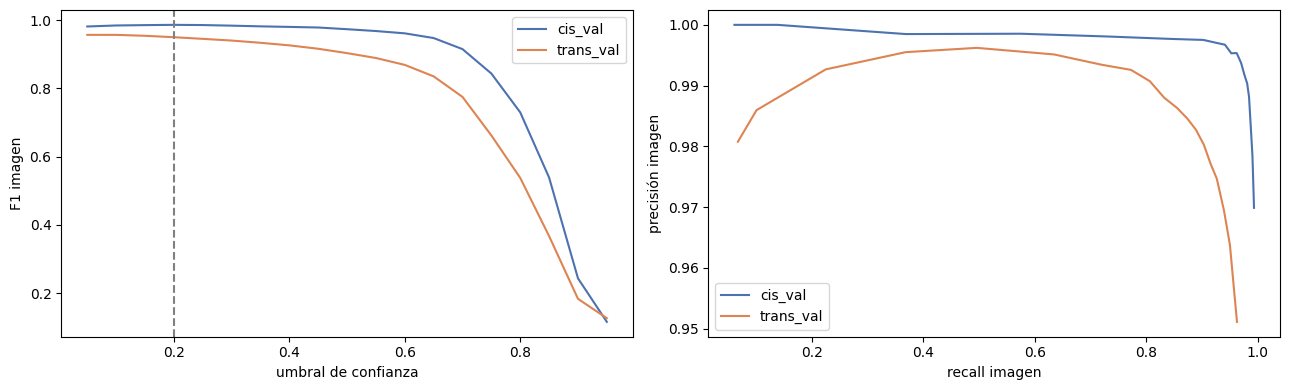

               tp     fp     fn     tn  precision  recall     f1  empty_false_alarm
cis_val    3510.0   42.0   56.0  267.0      0.988   0.984  0.986              0.136
trans_val  8352.0  217.0  662.0  664.0      0.975   0.927  0.950              0.246

empty_false_alarm = fracción de imágenes vacías en las que el modelo "ve" un animal.


In [ ]:
preds = {s: U.predict_split(BEST, s, RUN, conf=0.05, force=True) for s in ['cis_val', 'trans_val']}
M = {s: meta[meta.split == s] for s in preds}
sweeps = {s: U.sweep_image_level(M[s], preds[s]) for s in preds}
CONF_FOR_IMAGE_LEVEL = float(sweeps['cis_val'].sort_values('f1', ascending=False).iloc[0]['thr'])
print('Umbral elegido en cis_val (máx F1):', CONF_FOR_IMAGE_LEVEL)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s, c in zip(sweeps, ['#4C72B0', '#DD8452']):
    ax[0].plot(sweeps[s]['thr'], sweeps[s]['f1'], label=s, color=c)
    ax[1].plot(sweeps[s]['recall'], sweeps[s]['precision'], label=s, color=c)
ax[0].axvline(CONF_FOR_IMAGE_LEVEL, ls='--', color='gray'); ax[0].set_xlabel('umbral de confianza'); ax[0].set_ylabel('F1 imagen'); ax[0].legend()
ax[1].set_xlabel('recall imagen'); ax[1].set_ylabel('precisión imagen'); ax[1].legend()
plt.tight_layout(); plt.show()

il = pd.DataFrame({s: U.image_level_metrics(M[s], preds[s], CONF_FOR_IMAGE_LEVEL) for s in preds}).T
print(il[['tp', 'fp', 'fn', 'tn', 'precision', 'recall', 'f1', 'empty_false_alarm']].round(3).to_string())
print('\nempty_false_alarm = fracción de imágenes vacías en las que el modelo "ve" un animal.')

## 7. Análisis cualitativo de errores en cámaras nuevas
- Falsos positivos sobre imágenes vacías con mayor confianza (¿el modelo alucina en fondos/vegetación/sombras?).
- Falsos negativos (animales no detectados), a menudo pequeños, lejanos u ocluidos.

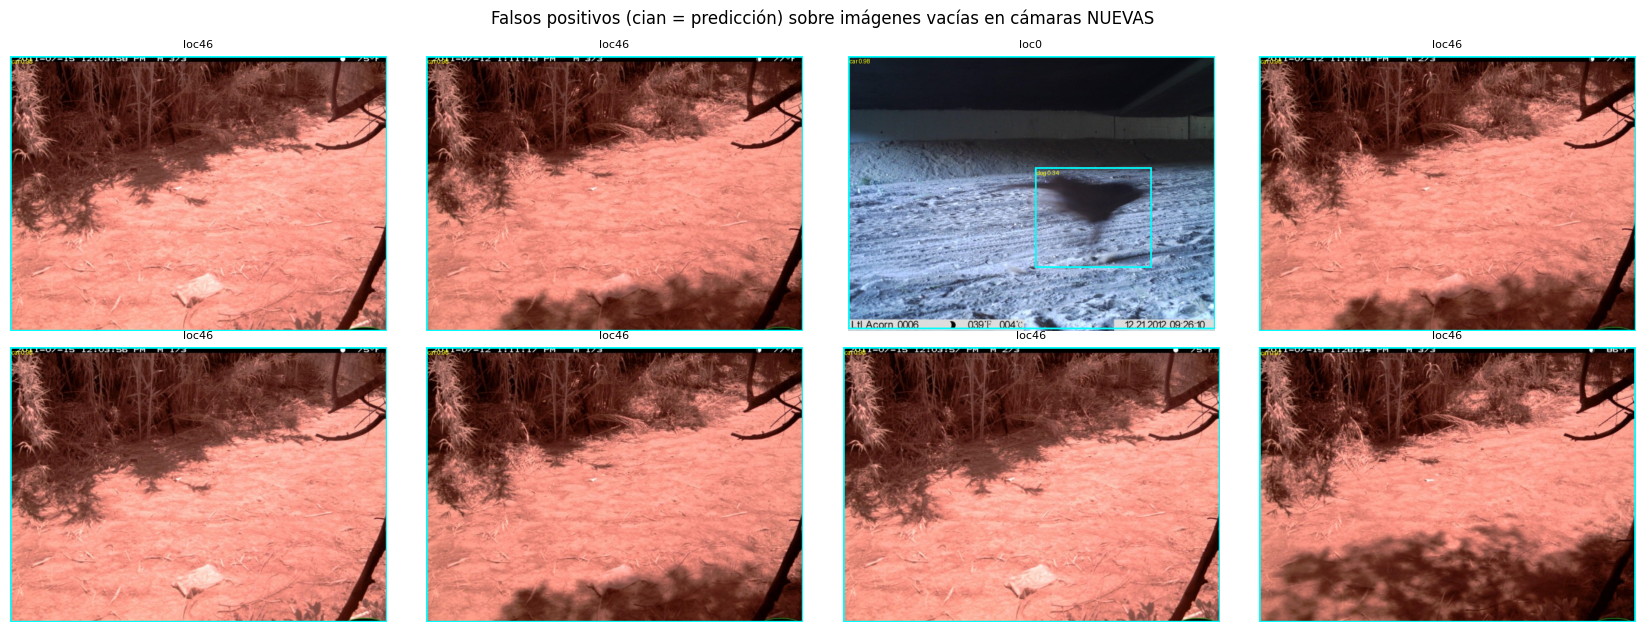

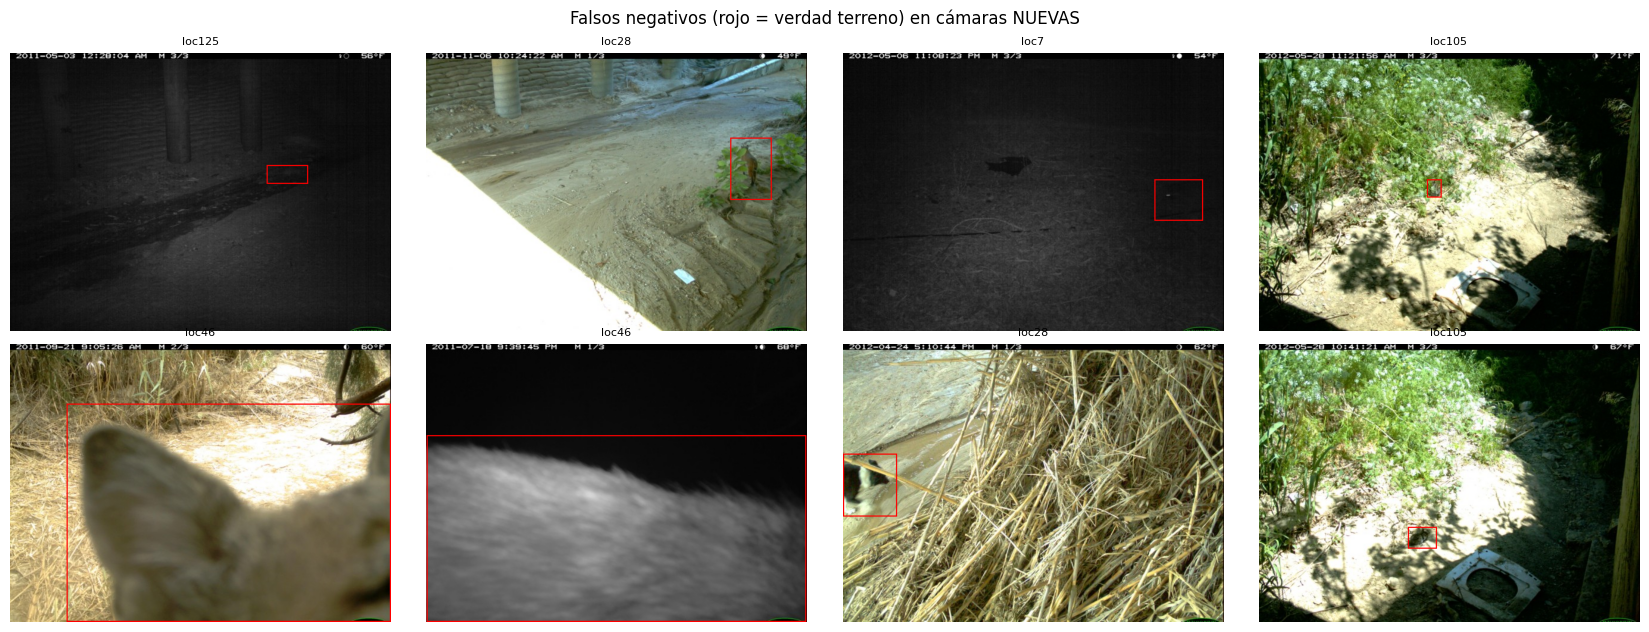

In [ ]:
def show(files, split, pdf, thr, title, cols=4):
    rows = (len(files) + cols - 1) // cols
    fig, axs = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.2 * rows))
    for a, f in zip(np.array(axs).ravel(), files):
        im = Image.open(U.LOCAL / 'images' / split / f).convert('RGB'); W, H = im.size
        d = ImageDraw.Draw(im)
        for r in pdf[(pdf.file == f) & (pdf.conf >= thr)].itertuples():
            d.rectangle([r.x1 * W, r.y1 * H, r.x2 * W, r.y2 * H], outline='cyan', width=3)
            d.text((r.x1 * W + 3, r.y1 * H + 3), f'{r.cls} {r.conf:.2f}', fill='yellow')
        lab = (U.LOCAL / 'labels' / split / (Path(f).stem + '.txt')).read_text().splitlines()
        for l in lab:
            c, xc, yc, w, h = l.split(); xc, yc, w, h = map(float, (xc, yc, w, h))
            d.rectangle([(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H], outline='red', width=2)
        a.imshow(im); a.axis('off'); a.set_title(f.split('__')[0], fontsize=8)
    for a in np.array(axs).ravel()[len(files):]: a.axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.show()

s = 'trans_val'; Mt = M[s]
empt = Mt[Mt.n_boxes == 0]['file']
fp_files = (preds[s][preds[s].file.isin(empt)].groupby('file').conf.max().sort_values(ascending=False).head(8).index.tolist())
show(fp_files, s, preds[s], CONF_FOR_IMAGE_LEVEL, 'Falsos positivos (cian = predicción) sobre imágenes vacías en cámaras NUEVAS')
pos = Mt[Mt.n_boxes > 0]['file']
detected = set(preds[s][preds[s].conf >= CONF_FOR_IMAGE_LEVEL].file)
fn_files = [f for f in pos if f not in detected]
fn_files = list(np.random.default_rng(0).choice(fn_files, size=min(8, len(fn_files)), replace=False)) if fn_files else []
show(fn_files, s, preds[s], CONF_FOR_IMAGE_LEVEL, 'Falsos negativos (rojo = verdad terreno) en cámaras NUEVAS')

## 8. Guardar resumen (lo consume el notebook 03)

In [ ]:
(U.DRIVE_DIR / 'summaries').mkdir(exist_ok=True)
summary = dict(config=CONFIG, conf_image_level=CONF_FOR_IMAGE_LEVEL,
               metrics={s: {k: v for k, v in r.items()} for s, r in res.items()},
               image_level={s: U.image_level_metrics(M[s], preds[s], CONF_FOR_IMAGE_LEVEL) for s in preds})
json.dump(summary, open(U.DRIVE_DIR / 'summaries' / f'{RUN}.json', 'w'), indent=2)
print('Guardado', U.DRIVE_DIR / 'summaries' / f'{RUN}.json')
print('Pesos:', BEST)

Guardado /content/drive/MyDrive/Dfoto/summaries/baseline.json
Pesos: /content/drive/MyDrive/Dfoto/runs/baseline/weights/best.pt
